## Gradient Boosting (next-day prediction)
Boosted trees fit each new tree to the previous trees' mistakes. Uses scikit-learn's `HistGradientBoostingClassifier` (fast, supports `class_weight`). Early stopping is off because its internal random validation split would mix future and past days.

In [1]:
import sys, json; sys.path.append("..")
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier

from src.prep_data import get_splits, make_model_pipeline
from src.evaluate_model import (best_threshold, threshold_for_recall, evaluate, full_report,
                                time_series_cv, tune_cv)

RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)

### 1. Load data (next-day target), clean, split chronologically

In [2]:
data = get_splits()
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
features = data["features"]
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])

Next-day target: dropped 9 rows with no following calendar day
Dropped 172 rows (6.8%) with >50% features missing (6 were positive); 2353 rows and 72 features remain
Remaining cells missing (to be imputed): 3.2%
train  1647 rows  1998-01-01 -> 2003-01-22  positives: 125  rate: 0.076
val     353 rows  2003-01-23 -> 2004-01-12  positives:  18  rate: 0.051
test    353 rows  2004-01-13 -> 2004-12-30  positives:  11  rate: 0.031


### 2. Tune hyperparameters with time-series CV
Small grid, scored by mean PR-AUC over 5 expanding-window folds on train + validation. The test set is not touched.
Imputation happens inside the pipeline (no scaling needed for trees).

In [3]:
def make_model(learning_rate=0.1, max_iter=100, max_depth=3, min_samples_leaf=20, l2_regularization=0.0):
    return make_model_pipeline(HistGradientBoostingClassifier(
        learning_rate=learning_rate, max_iter=max_iter, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
        l2_regularization=l2_regularization, class_weight="balanced", early_stopping=False, random_state=42), scale=False)

param_grid = {"learning_rate": [0.01, 0.03, 0.1], "max_iter": [100, 300], "max_depth": [1, 2, 3],
              "min_samples_leaf": [20, 50], "l2_regularization": [0.0, 1.0]}
tuning = tune_cv(make_model, param_grid, X_dev, y_dev)
tuning.head(10).round(3)

Tried 72 settings. Best: {'l2_regularization': 1.0, 'learning_rate': 0.01, 'max_depth': 2.0, 'max_iter': 300.0, 'min_samples_leaf': 50.0} -> CV PR-AUC 0.337 ± 0.091


,l2_regularization,learning_rate,max_depth,max_iter,min_samples_leaf,cv_pr_auc,cv_pr_auc_std,cv_roc_auc
0,1.0,0.01,2,300,50,0.337,0.091,0.841
1,0.0,0.03,2,100,20,0.337,0.097,0.840
2,1.0,0.03,2,100,50,0.333,0.098,0.841
3,1.0,0.01,2,300,20,0.330,0.095,0.840
4,0.0,0.01,2,300,20,0.330,0.110,0.839
5,0.0,0.03,3,100,50,0.325,0.088,0.835
6,1.0,0.03,2,100,20,0.325,0.083,0.840
7,0.0,0.10,3,300,20,0.324,0.067,0.816
8,0.0,0.03,2,100,50,0.322,0.096,0.837
9,0.0,0.01,2,300,50,0.321,0.097,0.838


In [4]:
def to_python(v):
    # DataFrame cells -> plain Python values (NaN -> None, 8.0 -> 8, numpy -> builtin)
    if v is None or (isinstance(v, float) and pd.isna(v)): return None
    v = v.item() if hasattr(v, "item") else v
    return int(v) if isinstance(v, float) and v.is_integer() and v >= 1 else v

best_params = {k: to_python(v) for k, v in
               tuning.drop(columns=["cv_pr_auc", "cv_pr_auc_std", "cv_roc_auc"]).iloc[0].items()}
print(best_params)

{'l2_regularization': 1, 'learning_rate': 0.01, 'max_depth': 2, 'max_iter': 300, 'min_samples_leaf': 50}


### 3. Fit the best setting on train, check train vs validation

In [5]:
model = make_model(**best_params).fit(X_train, y_train)
p_train = model.predict_proba(X_train)[:, 1]
p_val   = model.predict_proba(X_val)[:, 1]
evaluate("train", y_train, p_train)
evaluate("val  ", y_val, p_val);

train: ROC-AUC=0.933  PR-AUC=0.519 (random=0.076)  @0.50: P=0.265 R=0.952 F1=0.415
val  : ROC-AUC=0.815  PR-AUC=0.279 (random=0.051)  @0.50: P=0.101 R=0.722 F1=0.177


### 4. Choose decision thresholds on validation
Two rules: best F1 (same as the baseline), and the highest threshold that still catches 70% of validation ozone days (warning-system view).

In [6]:
thr_f1, f1 = best_threshold(y_val, p_val)
thr_r70, prec_r70 = threshold_for_recall(y_val, p_val, 0.70)
print(f"Best-F1 threshold: {thr_f1:.3f} (val F1={f1:.3f})")
print(f"Recall-70% threshold: {thr_r70:.3f} (val precision={prec_r70:.3f})")

Best-F1 threshold: 0.798 (val F1=0.457)
Recall-70% threshold: 0.527 (val precision=0.108)


### 5. Test-set evaluation
2004 has 11 next-day ozone days, so treat these numbers as noisy.

In [7]:
p_test = model.predict_proba(X_test)[:, 1]
res_f1  = evaluate("test @best-F1  ", y_test, p_test, thr_f1)
res_r70 = evaluate("test @recall-70", y_test, p_test, thr_r70)
full_report(y_test, p_test, thr_f1)

test @best-F1  : ROC-AUC=0.968  PR-AUC=0.682 (random=0.031)  @0.80: P=0.474 R=0.818 F1=0.600
test @recall-70: ROC-AUC=0.968  PR-AUC=0.682 (random=0.031)  @0.53: P=0.110 R=1.000 F1=0.198
Confusion matrix (rows=actual, cols=predicted):
 [[332  10]
 [  2   9]]
              precision    recall  f1-score   support

           0      0.994     0.971     0.982       342
           1      0.474     0.818     0.600        11

    accuracy                          0.966       353
   macro avg      0.734     0.894     0.791       353
weighted avg      0.978     0.966     0.970       353



### 6. Time-series CV folds for the chosen setting

In [8]:
cv = time_series_cv(make_model(**best_params), X_dev, y_dev, n_splits=5)
display(cv); print(cv[["roc_auc", "pr_auc"]].agg(["mean", "std"]).round(3))

,fold,n_test,positives,roc_auc,pr_auc
0,1,333,29,0.857248,0.457825
1,2,333,39,0.864512,0.399550
2,3,333,16,0.813289,0.293256
3,4,333,9,0.867627,0.227437
4,5,333,18,0.802822,0.307956


      roc_auc  pr_auc
mean    0.841   0.337
std     0.031   0.091


### 7. Feature importance (permutation, on validation)
How much validation PR-AUC drops when each feature is shuffled. Hourly features are strongly correlated, so importance gets shared among neighbours (e.g. T13–T16); read groups, not single columns.

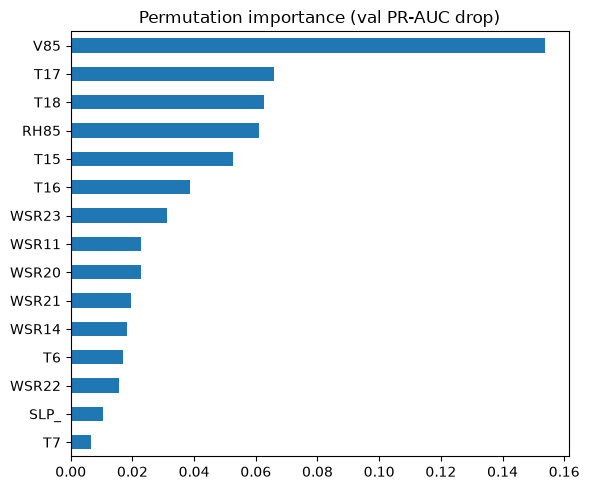

V85      0.1537
T17      0.0660
T18      0.0628
RH85     0.0609
T15      0.0527
T16      0.0386
WSR23    0.0311
WSR11    0.0229
WSR20    0.0227
WSR21    0.0196
dtype: float64

In [9]:
perm = permutation_importance(model, X_val, y_val, scoring="average_precision", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=features).sort_values()
imp.tail(15).plot.barh(figsize=(6, 5)); plt.title("Permutation importance (val PR-AUC drop)"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(10).round(4)

### 8. Save chosen settings for the comparison notebook

In [10]:
json.dump({"params": best_params, "thr_f1": float(thr_f1), "thr_r70": float(thr_r70)},
          open(RESULTS / "gradient_boosting_best.json", "w"), indent=2, default=str)

## Summary

**Tuning:** 72 settings, scored by 5-fold time-series CV PR-AUC on train + validation. Best: `learning_rate=0.01, max_iter=300, max_depth=2, min_samples_leaf=50, l2_regularization=1.0` (`class_weight="balanced"`).
The grid was widened to include `learning_rate=0.01` and `max_depth=1` after a first run picked the most constrained corner of a smaller grid. Depth-1 stumps never rank near the top, and the winner ties the previous best (`learning_rate=0.03, max_iter=100`, the same total learning rate × trees), so CV PR-AUC has plateaued at ~0.337.

**Results:**
| | ROC-AUC | PR-AUC | Random PR-AUC |
|---|---|---|---|
| Train | 0.933 | 0.519 | 0.076 |
| Validation | 0.815 | 0.279 | 0.051 |
| Test | 0.968 | 0.682 | 0.031 |
| 5-fold CV | 0.841 ± 0.031 | 0.337 ± 0.091 | ~0.07 |

At the best-F1 validation threshold (0.80): test precision 0.47, recall 0.82 (9 of 11 ozone days caught, 19 warnings).

**Important features:** V85 again first, then late-afternoon temperatures (T15–T18) and RH85 (humidity at 850 hPa).

**Caveats:** Validation PR-AUC (0.279) is the weakest of the three models, while test is the strongest: with 18 and 11 positives these single-split numbers swing a lot. CV is the fairer comparison (see `06_model_comparison.ipynb`). Validation was part of the tuning data, so validation metrics are slightly optimistic; the test set was not used for any choice.
